# 2. SIFT (Scale-Invariant Feature Transform) con Bolsa de Palabras Visuales (BoVW)
### Clasificación de Categorías de Imágenes: Manzanas, Perros y Personas

Este cuaderno implementa la solución completa de **Image Detection / Classification** utilizando **SIFT** y el modelo de **Bolsa de Palabras Visuales (Bag of Visual Words - BoVW)**:
- **Entrada**: Una imagen cualquiera.
- **Salida**: La clase predicha a la que pertenece la imagen (`apples`, `dogs` o `people`).

#### ¿Por qué Bolsa de Palabras Visuales (BoVW) para clasificar imágenes?
SIFT extrae un número variable de puntos clave locales por imagen (descriptores de 128 dimensiones). Como distintas imágenes de una misma clase no comparten puntos en las mismas posiciones espaciales, no se pueden comparar directamente fila por fila.
Con BoVW:
1. Agrupamos los descriptores de entrenamiento con K-Means para crear un **vocabulario visual** (diccionario de palabras visuales).
2. Cuantizamos cada imagen en un **histograma de frecuencias de palabras visuales**, produciendo un vector de longitud fija ($k = 150$) normalizado en norma $L_2$.
3. Entrenamos un clasificador SVM para predecir la clase de cualquier imagen.



In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

from dataset import load_split
from sift_pipeline import SIFTBoVWPipeline

def show_image(img, title=None):
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if len(img.shape) == 3 else img
    plt.figure(figsize=(5, 5))
    plt.imshow(img_rgb)
    plt.axis('off')
    if title:
        plt.title(title, fontsize=12, fontweight='bold')
    plt.show()



## Paso 1: Carga de Datos y Visualización de Puntos Clave SIFT


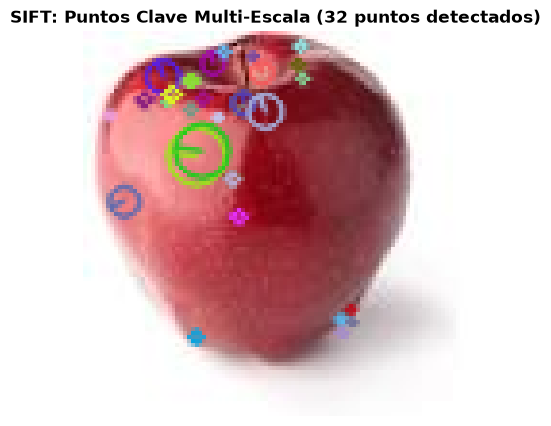

In [2]:
train_imgs, train_lbls, classes, _ = load_split("train")
test_imgs, test_lbls, _, _ = load_split("test")

sift = cv2.SIFT_create(nfeatures=400)
sample_img = train_imgs[0]
gray = cv2.cvtColor(sample_img, cv2.COLOR_BGR2GRAY)
kps, descs = sift.detectAndCompute(gray, None)

img_kps = cv2.drawKeypoints(sample_img, kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
show_image(img_kps, title=f"SIFT: Puntos Clave Multi-Escala ({len(kps)} puntos detectados)")



## Paso 2: Creación del Vocabulario Visual y Entrenamiento del Clasificador BoVW


In [ ]:
bovw_pipeline = SIFTBoVWPipeline(nfeatures=400, vocab_size=150)
print("Construyendo vocabulario visual con K-Means y entrenando clasificador SVM...")
train_info = bovw_pipeline.train(train_imgs, train_lbls, C=1.0)
print(f"Entrenamiento completado en {train_info['train_time_sec']:.2f} segundos!")
print(f"Vocabulario visual: {train_info['vocab_size']} palabras visuales")



Construyendo vocabulario visual con K-Means y entrenando clasificador SVM...


## Paso 3: Evaluación en el Conjunto de Prueba


In [ ]:
eval_res = bovw_pipeline.evaluate(test_imgs, test_lbls)
print(f"Exactitud en Prueba SIFT BoVW (Accuracy): {eval_res['accuracy'] * 100:.2f}%")
print(f"Latencia promedio por imagen:            {eval_res['avg_time_per_image_ms']:.2f} ms/imagen")
print("Reporte de Clasificación por Clase:")
print(classification_report(test_lbls, eval_res['predictions'], target_names=bovw_pipeline.classes_))

# Matriz de confusión
cm = np.array(eval_res["confusion_matrix"])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Purples")
ax.set_xticks(range(len(classes)))
ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, fontsize=11)
ax.set_yticklabels(classes, fontsize=11)
plt.xlabel("Clase Predicha", fontsize=11)
plt.ylabel("Clase Real", fontsize=11)
plt.title("Matriz de Confusión SIFT + BoVW", fontsize=12, fontweight='bold')
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="red" if i != j else "black", fontweight='bold')
plt.colorbar(im)
plt.tight_layout()
plt.show()



## Paso 4: Demostración de Clasificación en Imágenes Individuales


In [ ]:
import random

for _ in range(3):
    idx = random.randrange(len(test_imgs))
    img = test_imgs[idx]
    true_label = test_lbls[idx]
    
    pred_label = bovw_pipeline.predict([img])[0]
    show_image(img, title=f"Real: {true_label.upper()} | Predicción SIFT: {pred_label.upper()}")



## Paso 5: Guardado del Modelo


In [ ]:
bovw_pipeline.save_model("sift_bovw_model.pkl")
sz = Path("sift_bovw_model.pkl").stat().st_size / (1024 * 1024)
print(f"Modelo guardado: sift_bovw_model.pkl ({sz:.2f} MB)")

